# The glass-box dynamic workflow

Most auto-interpretation tools hand you curves with no idea *how*. This library's workflow
**auto-detects the curves you have, picks a method per step, and records every decision**, so the
whole interpretation is a structured, replayable trace. This notebook runs it on a real well, reads
the trace, and then runs it on a sparser well to watch the routing adapt. It's all library calls.

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow

GEO = REPO / "petrophys" / "data" / "geolink"
well = read_las(GEO / "30_6-5.las")
result = run_dynamic_workflow(well, lithology="clastic")
print("executed:", [s.step for s in result.steps_executed])
print("skipped :", result.steps_skipped)

executed: ['temperature', 'bad_hole', 'vclay', 'rcl', 'porosity', 'lithology', 'core_correction', 'rw', 'invasion', 'saturation', 'permeability', 'rock_quality', 'bvw', 'mhi', 'net_pay']
skipped : ['rmf', 'hc_correction', 'porosity_refinement']


## The decision trace as a table

`result.to_dataframe()` is the interpretation's audit log, method chosen and curves consumed/produced per step.

In [2]:
result.to_dataframe()[["Step", "Status", "Method", "Input Curves", "Output Curves"]]

,Step,Status,Method,Input Curves,Output Curves
0,temperature,OK,fallback_geothermal_gradient,,TEMP
1,bad_hole,OK,caliper_drho_flags,"CALI, BS, DRHO, RHOB, PEF",BAD_HOLE
2,vclay,OK,linear,"GR, SP, NPHI, RHOB","VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_..."
3,rcl,OK,lithology_shale_median_rt,"RDEP, VCL",
4,porosity,OK,component_based,"NPHI, RHOB, DTC, VCL","PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
5,lithology,OK,multi_mineral_solver,"RHOB, VCL, NPHI, PHIE, PEF, DTC","VQUAR, VCALC, VDOLO, VANHY, MMQC"
6,core_correction,OK,same_well_core_correction,PHIE,"PHIE_CC, PERM_CC"
7,rw,OK,rwa_clean_wet_adaptive,"RDEP, PHIE_CC, VCL",RW
8,invasion,OK,rxo_rt_ratio,"RDEP, RSHA+RMED",INVASION_RATIO
9,saturation,OK,archie+indonesia+dual_water,"RDEP, PHIE_CC, VCL","SW, SXO"


Steps it could not run were skipped **with reasons**:

In [3]:
result.specific_steps_skipped

{}

## Why each number was produced

Every step keeps a human-readable `decisions` log, emitted by the code as it branches, so it
always matches what ran. The water-resistivity step even reports the **regime** it detected
(all-wet vs. a hydrocarbon leg) and the statistic it used to choose its percentile.

In [4]:
for s in result.steps_executed:
    if s.step in ("bad_hole", "vclay", "rw", "porosity"):
        print(f"=== {s.step}  (method: {s.method}) ===")
        for d in s.decisions:
            print("   •", d)
        print()

=== bad_hole  (method: caliper_drho_flags) ===
   • 12631 bad-hole samples flagged out of 22176

=== vclay  (method: linear) ===
   • GR_min = 21.6 (auto, P5 of GR)
   • GR_max = 115.3 (auto, P95 of GR)
   • GR method: linear
   • SP method: enabled
   • N-D method: enabled
   • SP_clean = 43.2 (auto, P5 of SP)
   • SP_shale = 111.6 (auto, P95 of SP)
   • Final VCL = neutron-density-primary (GR where gas invalidates N-D), range: 0.000 - 1.000

=== porosity  (method: component_based) ===
   • Initial porosity pass used an available lithology log for matrix endpoints
   • PHIN = clip(NPHI - nphi_ma(depth), 0, 0.6) using lithology-specific matrix neutron endpoints
   • PHID = (rho_ma(depth) - RHOB) / (rho_ma(depth) - rho_fl)
   • PHIS from Wyllie time-average equation using dt_ma(depth)
   • PHIT = adaptive(PHIN, PHID) with per-sample fallback: density_from_missing_phin=4755, density_from_gas_crossover=319, weighted_nd=17097, neutron_from_missing_phid=5, nan=0
   • PHIE = PHIT - VCL * phi

## The same trace as structured data (for tooling / LLMs)

`to_trace_dict()` / `to_json()` serialise the whole run: schema, steps, methods, parameters, decisions, and per-curve summaries.

In [5]:
trace = result.to_trace_dict(include_curves=["PHIE"])
rw = next(s for s in trace["steps"] if s["step"] == "rw")
{"executed": trace["executed_steps"],
 "rw_method": rw["method"],
 "rw_params": {k: rw["parameters"].get(k) for k in ("rwa_regime", "rwa_percentile", "rw_from_rwa")},
 "PHIE_p50": round(trace["curve_summaries"]["PHIE"]["data"]["p50"], 3)}

{'executed': ['temperature',
  'bad_hole',
  'vclay',
  'rcl',
  'porosity',
  'lithology',
  'core_correction',
  'rw',
  'invasion',
  'saturation',
  'permeability',
  'rock_quality',
  'bvw',
  'mhi',
  'net_pay'],
 'rw_method': 'rwa_clean_wet_adaptive',
 'rw_params': {'rwa_regime': 'narrow_spread_all_wet_median',
  'rwa_percentile': 50.0,
  'rw_from_rwa': 0.19497197097166521},
 'PHIE_p50': 0.186}

## The interpreted well

One library call renders the full composite: lithology, the raw logs, and every computed track (VCL, porosity with the core plugs, Sw, permeability, mineral volumes, pay flags).

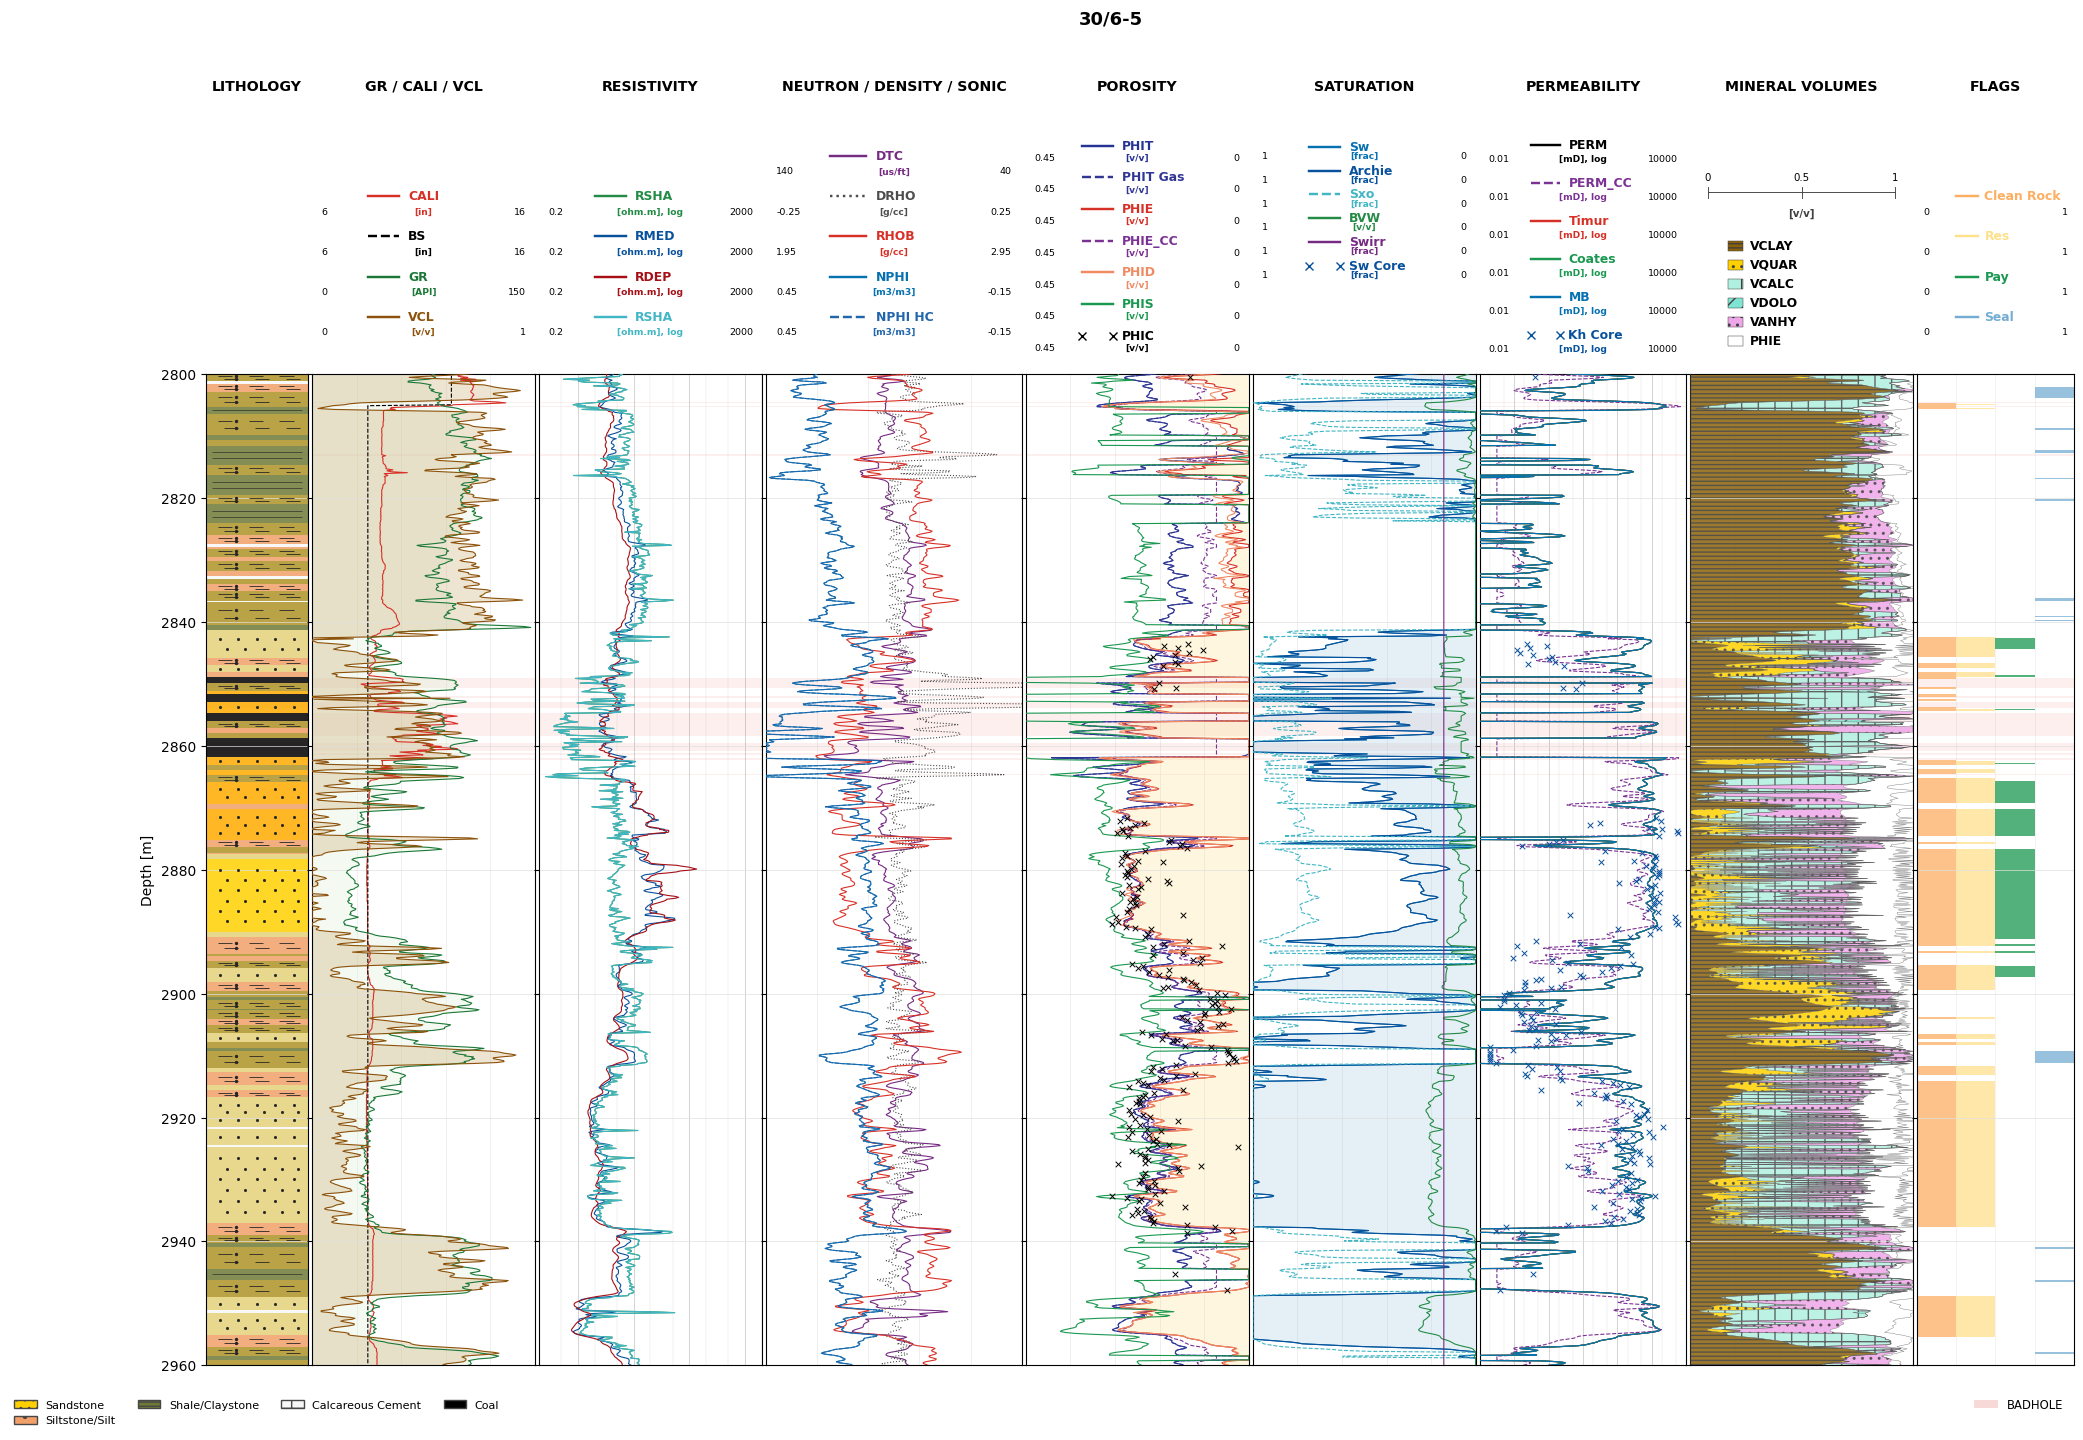

In [6]:
from petrophys.visualization import create_log_viewer
create_log_viewer(well, template_defaults="full", depth_range=(2800, 2960));

## The workflow adapts: a sparser well

Well **16/7-1** has no neutron, no PEF, no core. Run the *same* workflow and the trace reroutes:
density-only porosity, no neutron-density clay, the core step gone, and the adaptive-Rw step
detects a hydrocarbon leg, so it switches from the median to the low-tail percentile. Nothing about
the call changed; the routing followed the data.

In [7]:
well2 = read_las(GEO / "16_7-1.las")
result2 = run_dynamic_workflow(well2, lithology="clastic")
def summary(w, res):
    rw = next((s for s in res.steps_executed if s.step == "rw"), None)
    poro = next((s for s in res.steps_executed if s.step == "porosity"), None)
    return {"curves": len(w.curves), "steps": len(res.steps_executed),
            "rw_regime": rw.parameters.get("rwa_regime") if rw else None,
            "porosity_method": poro.method if poro else None,
            "has_core_step": "core_correction" in [s.step for s in res.steps_executed]}
pd.DataFrame({"30/6-5": summary(well, result), "16/7-1": summary(well2, result2)})

,30/6-5,16/7-1
curves,60,46
steps,15,14
rw_regime,narrow_spread_all_wet_median,wide_spread_hc_leg_low_tail
porosity_method,component_based,component_based
has_core_step,True,False


**Takeaways**

* The workflow **auto-routes** on the available curves and **records every decision**: nothing is
  unexplained.
* The trace is a table (`to_dataframe`), JSON (`to_trace_dict` / `to_json`), or markdown
  (`to_markdown`), auditable by a human or a machine.
* Because the decisions are emitted by the running code, the trace can never drift from what ran.